# DSCI 552 Homework 4

**Name:** Yufan Yao  
**USC ID:** 1450125536  
**GitHub Username:** yufanyao-cloud


In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
plt.style.use("seaborn-v0_8-whitegrid")

RANDOM_STATE = 552
DATA_DIR = Path("../data/AReM")

ACTIVITIES = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking",
]

COLUMNS = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]

SIGNAL_COLUMNS = COLUMNS[1:]
FEATURE_TYPES = ["min", "max", "mean", "median", "std", "q1", "q3"]

print("Data directory:", DATA_DIR.resolve())
print("Data directory exists:", DATA_DIR.exists())


Data directory: C:\Users\yaofa\OneDrive\Desktop\HW4\data\AReM
Data directory exists: True


## 1. Data Preparation from Homework 3


In [2]:
def dataset_number(file_path):
    """Extract the number from a name such as dataset12.csv."""
    return int(file_path.stem.replace("dataset", ""))


def read_arem_file(file_path):
    """Read and clean one AReM data file."""
    df = pd.read_csv(
        file_path,
        comment="#",
        header=None,
        names=range(8),
        sep=r"[,\s]+",
        engine="python",
        skip_blank_lines=True,
    )

    # A trailing comma in a few files creates an empty eighth column.
    df = df.dropna(axis=1, how="all")

    if df.shape[1] != 7:
        raise ValueError(
            f"{file_path} should have 7 columns, but {df.shape[1]} were found."
        )

    df.columns = COLUMNS
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.dropna(how="all").reset_index(drop=True)

    if df.isna().any().any():
        raise ValueError(f"Missing or nonnumeric values were found in {file_path}.")

    return df


def assign_set(activity, number):
    """Apply the train/test split required by the assignment."""
    if activity in ["bending1", "bending2"]:
        return "test" if number in [1, 2] else "train"
    return "test" if number in [1, 2, 3] else "train"


if not DATA_DIR.exists():
    raise FileNotFoundError(f"Cannot find the data folder: {DATA_DIR}")

instance_rows = []

for activity in ACTIVITIES:
    files = sorted(
        (DATA_DIR / activity).glob("dataset*.csv"),
        key=dataset_number,
    )

    for file_path in files:
        number = dataset_number(file_path)
        instance_rows.append(
            {
                "activity": activity,
                "dataset": file_path.stem,
                "set": assign_set(activity, number),
                "file_path": file_path,
                "binary_label": int(activity in ["bending1", "bending2"]),
            }
        )

instance_table = pd.DataFrame(instance_rows)

display(pd.crosstab(instance_table["activity"], instance_table["set"], margins=True))
print("Total instances:", len(instance_table))
print("Training instances:", (instance_table["set"] == "train").sum())
print("Test instances:", (instance_table["set"] == "test").sum())

assert len(instance_table) == 88
assert (instance_table["set"] == "train").sum() == 69
assert (instance_table["set"] == "test").sum() == 19


set,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


Total instances: 88
Training instances: 69
Test instances: 19


In [3]:
# Read each file once and reuse it in the later experiments.
raw_data = {
    str(row.file_path): read_arem_file(row.file_path)
    for row in instance_table.itertuples()
}

row_counts = pd.Series(
    [len(df) for df in raw_data.values()],
    name="number_of_instances",
).value_counts().sort_index()

display(row_counts.rename_axis("rows").to_frame())


,count
rows,
479,1
480,87


In [4]:
def segment_statistics(values):
    """Calculate the seven required time-domain features."""
    return {
        "min": np.min(values),
        "max": np.max(values),
        "mean": np.mean(values),
        "median": np.median(values),
        "std": np.std(values, ddof=1),
        "q1": np.quantile(values, 0.25),
        "q3": np.quantile(values, 0.75),
    }


def extract_segment_features(
    df,
    number_of_segments,
    feature_types=FEATURE_TYPES,
    series_numbers=(1, 2, 3, 4, 5, 6),
):
    """Split each requested series and extract features from every segment."""
    feature_row = {}

    for series_number in series_numbers:
        column = SIGNAL_COLUMNS[series_number - 1]
        values = df[column].to_numpy()
        segments = np.array_split(values, number_of_segments)

        for part_number, segment in enumerate(segments, start=1):
            statistics = segment_statistics(segment)

            for feature_type in feature_types:
                name = f"{feature_type}_ts{series_number}_part{part_number}"
                feature_row[name] = statistics[feature_type]

    return feature_row


def build_feature_data(
    number_of_segments,
    set_name,
    feature_types=FEATURE_TYPES,
    series_numbers=(1, 2, 3, 4, 5, 6),
):
    """Build one feature matrix from the requested train or test instances."""
    rows = []
    labels_binary = []
    labels_multiclass = []
    metadata = []

    selected_instances = instance_table[instance_table["set"] == set_name]

    for instance in selected_instances.itertuples():
        df = raw_data[str(instance.file_path)]
        rows.append(
            extract_segment_features(
                df,
                number_of_segments,
                feature_types=feature_types,
                series_numbers=series_numbers,
            )
        )
        labels_binary.append(instance.binary_label)
        labels_multiclass.append(instance.activity)
        metadata.append(f"{instance.activity}/{instance.dataset}")

    return (
        pd.DataFrame(rows),
        np.asarray(labels_binary),
        np.asarray(labels_multiclass),
        metadata,
    )


## 2. Time Series Classification Part 2

### 2(a) Binary Classification Using Logistic Regression

The positive class is bending (`bending1` or `bending2`). All other
activities form the negative class.


#### 2(a)(i) Scatter Plots for the Original Time Series

Minimum, mean, and maximum are extracted from time series 1, 2, and 6 of the
training instances.


In [5]:
X_scatter_1, y_scatter_1, _, _ = build_feature_data(
    number_of_segments=1,
    set_name="train",
    feature_types=["min", "mean", "max"],
    series_numbers=(1, 2, 6),
)

scatter_data_1 = X_scatter_1.copy()
scatter_data_1["class"] = np.where(y_scatter_1 == 1, "bending", "other")

def plot_three_features(data, series_number, part_number, title):
    """Draw the three non-repeated scatter plots required here."""
    min_column = f"min_ts{series_number}_part{part_number}"
    max_column = f"max_ts{series_number}_part{part_number}"
    mean_column = f"mean_ts{series_number}_part{part_number}"

    plot_pairs = [
        (min_column, max_column, "Minimum", "Maximum"),
        (min_column, mean_column, "Minimum", "Mean"),
        (max_column, mean_column, "Maximum", "Mean"),
    ]
    colors = {"other": "steelblue", "bending": "darkorange"}
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

    for axis, (x_column, y_column, x_label, y_label) in zip(
        axes, plot_pairs
    ):
        for class_name in ["other", "bending"]:
            class_data = data[data["class"] == class_name]
            axis.scatter(
                class_data[x_column],
                class_data[y_column],
                color=colors[class_name],
                label=class_name,
                alpha=0.75,
                s=30,
            )
        axis.set_xlabel(x_label)
        axis.set_ylabel(y_label)
        axis.set_title(f"{x_label} vs. {y_label}")

    axes[0].legend()
    fig.suptitle(title)
    fig.subplots_adjust(
        left=0.07,
        right=0.98,
        bottom=0.18,
        top=0.78,
        wspace=0.30,
    )
    plt.show()


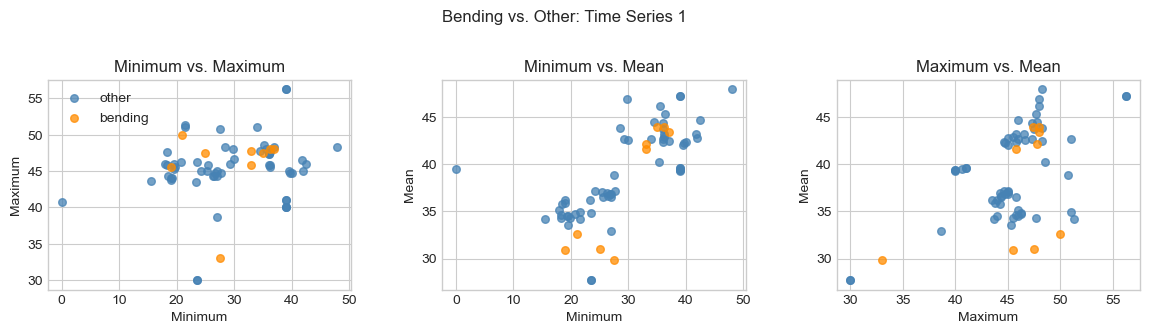

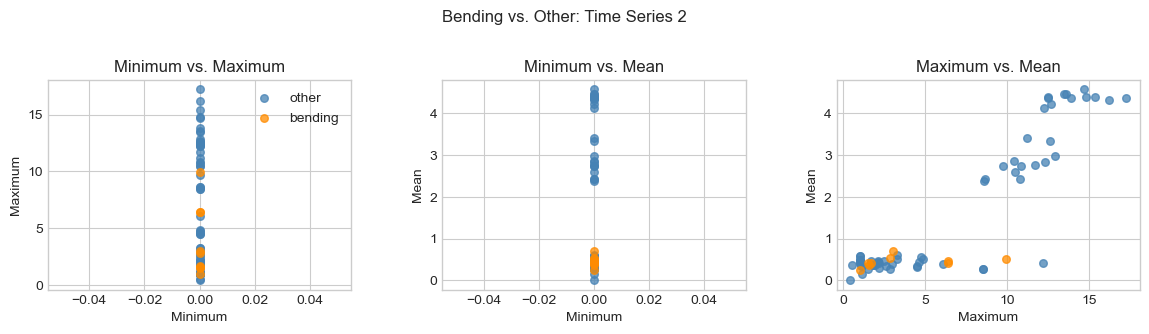

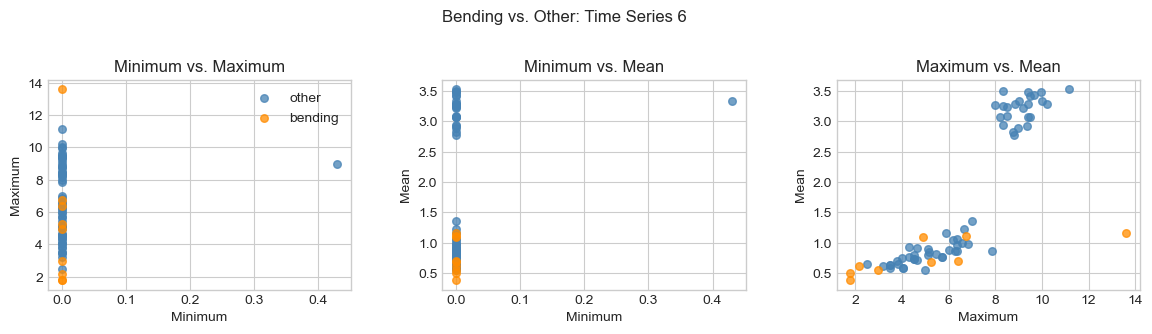

In [6]:
for series_number in [1, 2, 6]:
    plot_three_features(
        scatter_data_1,
        series_number=series_number,
        part_number=1,
        title=f"Bending vs. Other: Time Series {series_number}",
    )


The plots show which combinations of the selected features provide visible
separation between bending and the other activities. Several plots may still
contain overlap, so the classifier uses multiple features together.


#### 2(a)(ii) Split Each Time Series into Two Parts

Splitting the series produces local summaries for the first and second halves
of each activity instance. Each segment and time series is shown separately
so the scatter plots remain readable.


In [7]:
X_scatter_2, y_scatter_2, _, _ = build_feature_data(
    number_of_segments=2,
    set_name="train",
    feature_types=["min", "mean", "max"],
    series_numbers=(1, 2, 6),
)

scatter_data_2 = X_scatter_2.copy()
scatter_data_2["class"] = np.where(y_scatter_2 == 1, "bending", "other")


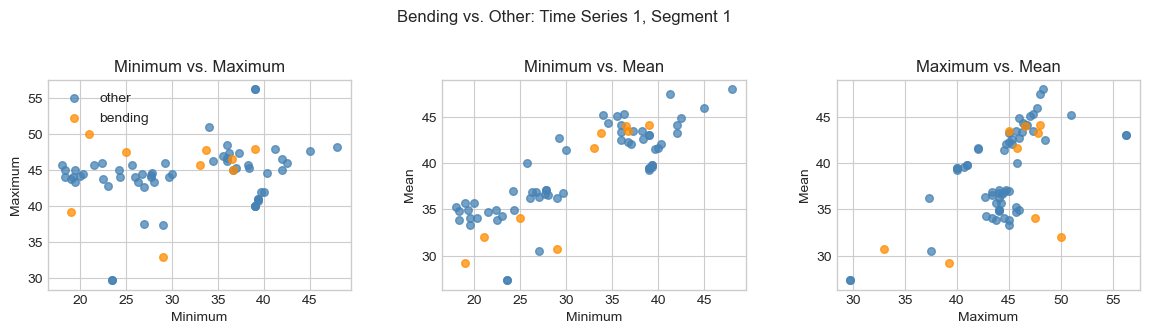

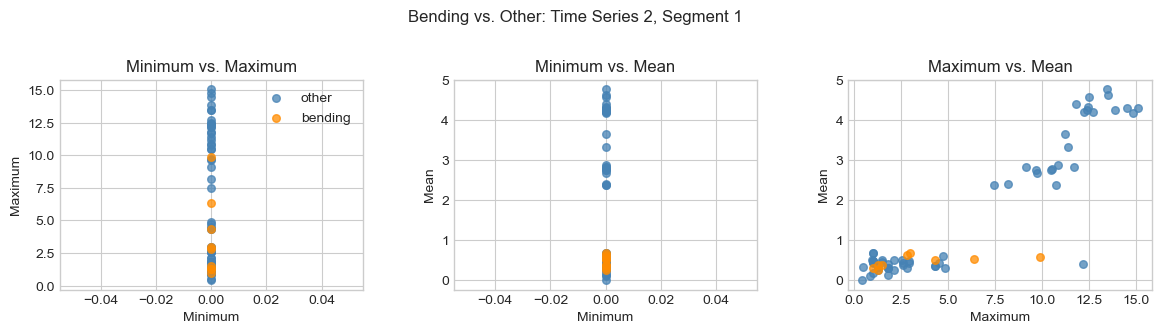

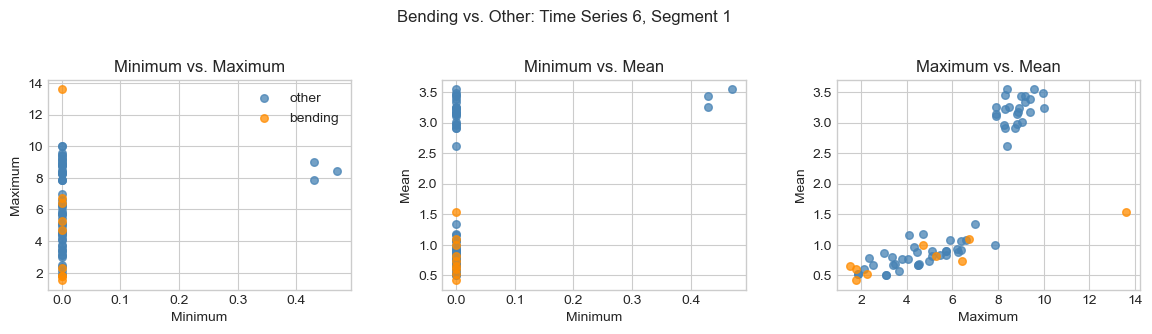

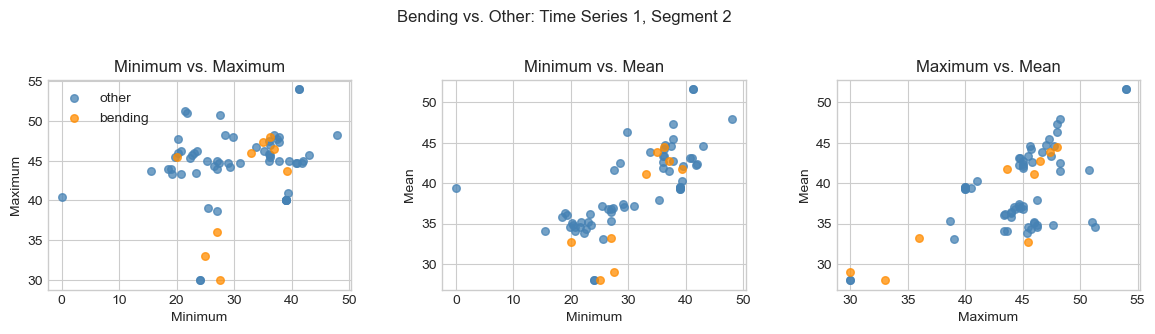

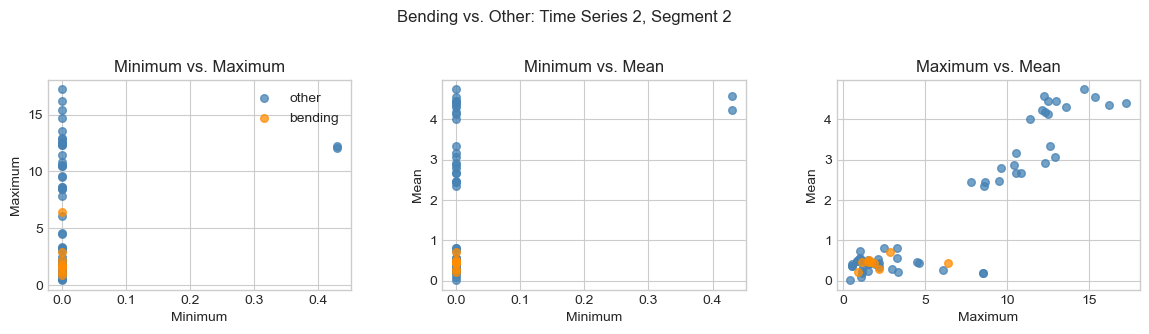

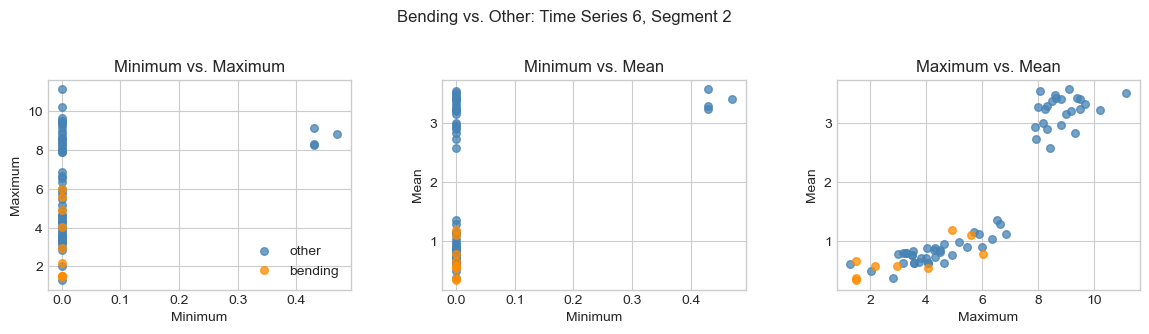

In [8]:
for part_number in [1, 2]:
    for series_number in [1, 2, 6]:
        plot_three_features(
            scatter_data_2,
            series_number=series_number,
            part_number=part_number,
            title=(
                f"Bending vs. Other: Time Series {series_number}, "
                f"Segment {part_number}"
            ),
        )


Compared with the plots in 2(a)(i), splitting each time series into two parts produces a noticeable but not universal improvement in class separation. In some plots, the bending observations form more distinct groups and show less overlap with the other activities. However, overlap is still present in several feature combinations.

The difference occurs because the original features summarize the entire activity instance with one minimum, maximum, and mean. After splitting, the features describe the first and second halves separately, so changes during different stages of the activity are preserved. Therefore, segmentation provides additional information that is lost when the whole time series is summarized as one segment, although it does not completely separate the two classes.

#### 2(a)(iii) Select the Best Pair of \(l\) and \(p\)

For each $l \in \{1,\ldots,20\}$, every time series is divided into $l$ approximately equal segments. This keeps the number of training instances unchanged but increases the number of features to $42l$.

Five-fold stratified cross-validation is used to select the best pair $(l,p)$, where $p$ is the number of features retained by RFE.

The correct method fits standardization, RFE, and logistic regression using only the training folds, and then evaluates the model on the validation fold. The wrong method performs feature selection before cross-validation because the validation data would influence the selected features and produce an overly optimistic accuracy.

Stratified cross-validation preserves approximately the same proportion of bending and other activities in every fold, which is important because the training set contains only 9 bending instances and 60 other instances.

In [9]:
binary_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

rfe_estimator = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=3000,
    random_state=RANDOM_STATE,
)

standard_pipeline = Pipeline(
    [
        ("scale", StandardScaler()),
        (
            "rfe",
            RFE(
                estimator=rfe_estimator,
                step=0.1,
            ),
        ),
        (
            "model",
            LogisticRegression(
                C=1e6,
                solver="liblinear",
                max_iter=3000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

standard_search_rows = []
standard_searches = {}

for number_of_segments in range(1, 21):
    X_train_l, y_train_l, _, _ = build_feature_data(
        number_of_segments,
        "train",
    )

    # The training set has 69 instances, so p is kept below the sample size.
    # This grid covers small models while keeping computation manageable.
    p_options = [
        p
        for p in [1, 2, 3, 5, 10, 15, 20, 30, 40, 50, 60]
        if p <= X_train_l.shape[1]
    ]

    search = GridSearchCV(
        estimator=standard_pipeline,
        param_grid={"rfe__n_features_to_select": p_options},
        scoring="accuracy",
        cv=binary_cv,
        n_jobs=-1,
    )
    search.fit(X_train_l, y_train_l)

    standard_searches[number_of_segments] = search
    standard_search_rows.append(
        {
            "l": number_of_segments,
            "p": search.best_params_["rfe__n_features_to_select"],
            "cv_accuracy": search.best_score_,
        }
    )

standard_cv_results = pd.DataFrame(standard_search_rows)
best_standard_row = standard_cv_results.loc[
    standard_cv_results["cv_accuracy"].idxmax()
]
best_l_standard = int(best_standard_row["l"])
best_p_standard = int(best_standard_row["p"])
best_standard_search = standard_searches[best_l_standard]
best_standard_model = best_standard_search.best_estimator_

display(
    standard_cv_results.sort_values(
        "cv_accuracy", ascending=False
    ).head(5).round(4)
)
print("Best l:", best_l_standard)
print("Best p:", best_p_standard)
print("Best CV accuracy:", round(best_standard_row["cv_accuracy"], 4))


,l,p,cv_accuracy
18,19,15,0.9714
19,20,40,0.9714
11,12,2,0.9714
0,1,2,0.9571
16,17,30,0.9571


Best l: 12
Best p: 2
Best CV accuracy: 0.9714


#### 2(a)(iv) Training Confusion Matrix, ROC, AUC, Coefficients, and P-values


Training accuracy: 0.9855
Training AUC: 0.9963


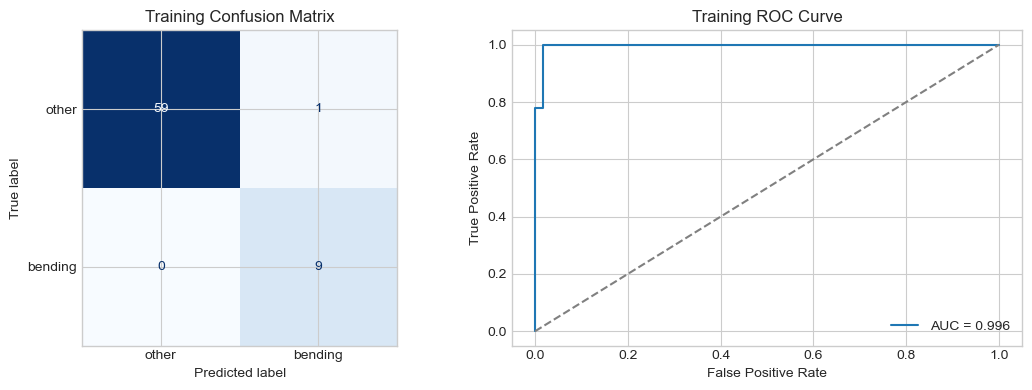

In [10]:
X_train_standard, y_train_binary, _, _ = build_feature_data(
    best_l_standard,
    "train",
)

train_prediction = best_standard_model.predict(X_train_standard)
train_probability = best_standard_model.predict_proba(X_train_standard)[:, 1]
train_accuracy = accuracy_score(y_train_binary, train_prediction)
train_auc = roc_auc_score(y_train_binary, train_probability)

print("Training accuracy:", round(train_accuracy, 4))
print("Training AUC:", round(train_auc, 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_train_binary,
    train_prediction,
    display_labels=["other", "bending"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Training Confusion Matrix")

fpr, tpr, _ = roc_curve(y_train_binary, train_probability)
axes[1].plot(fpr, tpr, label=f"AUC = {train_auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Training ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()


In [11]:
# Extract the selected features and estimate coefficients and p-values
# with the same statsmodels model.
scaler_standard = best_standard_model.named_steps["scale"]
rfe_standard = best_standard_model.named_steps["rfe"]

selected_mask = rfe_standard.support_
selected_feature_names = X_train_standard.columns[selected_mask]

X_train_scaled = scaler_standard.transform(X_train_standard)
X_train_selected = X_train_scaled[:, selected_mask]

try:
    inference_model = sm.GLM(
        y_train_binary,
        sm.add_constant(X_train_selected),
        family=sm.families.Binomial(),
    ).fit()

    parameter_table = pd.DataFrame(
        {
            "feature": ["intercept", *selected_feature_names],
            "coefficient": inference_model.params,
            "p_value": inference_model.pvalues,
        }
    )
    display(parameter_table.round(5))
except Exception as error:
    print("Coefficients and p-values could not be estimated reliably.")
    print("Possible reason: complete or near-complete separation.")
    print("Error:", error)


,feature,coefficient,p_value
0,intercept,-10.26904,0.16340
1,q1_ts1_part3,-2.25073,0.28501
2,q1_ts5_part2,10.93156,0.13216


The final RFE model retained two features. However, their p-values are greater
than 0.05, so they are not individually significant at the 5% level. This may
be caused by the small number of bending instances and possible separation
between the classes. RFE selects features based on classification performance
rather than individual p-values.


#### 2(a)(v) Test the Classifier


In [12]:
X_test_standard, y_test_binary, _, _ = build_feature_data(
    best_l_standard,
    "test",
)

test_prediction = best_standard_model.predict(X_test_standard)
test_probability = best_standard_model.predict_proba(X_test_standard)[:, 1]
test_accuracy = accuracy_score(y_test_binary, test_prediction)
test_auc = roc_auc_score(y_test_binary, test_probability)

comparison_standard = pd.DataFrame(
    {
        "measure": ["Cross-validation accuracy", "Test accuracy", "Test AUC"],
        "value": [best_standard_row["cv_accuracy"], test_accuracy, test_auc],
    }
)

display(comparison_standard.round(4))
display(pd.DataFrame(
    confusion_matrix(y_test_binary, test_prediction),
    index=["Actual other", "Actual bending"],
    columns=["Predicted other", "Predicted bending"],
))


,measure,value
0,Cross-validation accuracy,0.9714
1,Test accuracy,0.9474
2,Test AUC,0.9833


,Predicted other,Predicted bending
Actual other,15,0
Actual bending,1,3


The test series are divided into the same number of segments selected using
the training data. The test accuracy is compared with cross-validation
accuracy; a large decrease would suggest that the cross-validation estimate
was optimistic.


#### 2(a)(vi) Check for Separation


In [13]:
extreme_probability_fraction = np.mean(
    (train_probability < 0.01) | (train_probability > 0.99)
)

print("Training accuracy:", round(train_accuracy, 4))
print(
    "Fraction of training probabilities below 0.01 or above 0.99:",
    round(extreme_probability_fraction, 4),
)

if train_accuracy == 1 and extreme_probability_fraction > 0.9:
    print("The classes appear strongly separated, which can destabilize coefficients.")
else:
    print("The diagnostic does not show complete separation for this fitted model.")


Training accuracy: 0.9855
Fraction of training probabilities below 0.01 or above 0.99: 0.913
The diagnostic does not show complete separation for this fitted model.


The classes are strongly but not completely separated. The training accuracy
is 98.55%, and 91.3% of the predicted probabilities are close to 0 or 1.
This near-separation may make the logistic regression coefficients unstable.

#### 2(a)(vii) Class Imbalance and Case-Control Sampling

Yes, the training data are imbalanced, with 60 other-activity instances and
only 9 bending instances. Case-control sampling was used to balance the two
classes during model fitting, and the intercept was adjusted to -22.1154 to
account for the original class proportions.

The adjusted model correctly classified all 9 bending instances and 59 of the
60 other instances. Only one other instance was incorrectly classified as
bending. The training AUC is 0.9944, indicating excellent separation between
the two classes.

,training_instances
other,60
bending,9


Adjusted case-control intercept: -22.1154
Case-control training AUC: 0.9944


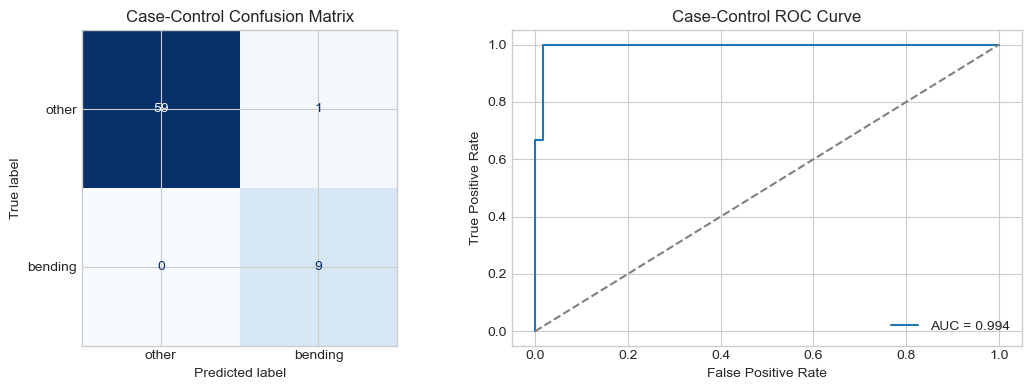

In [14]:
class_counts = pd.Series(y_train_binary).value_counts().sort_index()
class_counts.index = ["other", "bending"]
display(class_counts.to_frame("training_instances"))

rng = np.random.default_rng(RANDOM_STATE)
positive_indices = np.where(y_train_binary == 1)[0]
negative_indices = np.where(y_train_binary == 0)[0]
sampled_negative_indices = rng.choice(
    negative_indices,
    size=len(positive_indices),
    replace=False,
)
case_control_indices = np.concatenate(
    [positive_indices, sampled_negative_indices]
)

case_control_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=3000,
    random_state=RANDOM_STATE,
)
case_control_model.fit(
    X_train_selected[case_control_indices],
    y_train_binary[case_control_indices],
)

population_prevalence = y_train_binary.mean()
sample_prevalence = y_train_binary[case_control_indices].mean()

intercept_adjustment = (
    np.log(population_prevalence / (1 - population_prevalence))
    - np.log(sample_prevalence / (1 - sample_prevalence))
)
adjusted_intercept = case_control_model.intercept_[0] + intercept_adjustment

case_control_score = (
    adjusted_intercept
    + X_train_selected @ case_control_model.coef_[0]
)
case_control_probability = 1 / (1 + np.exp(-case_control_score))
case_control_prediction = (case_control_probability >= 0.5).astype(int)
case_control_auc = roc_auc_score(y_train_binary, case_control_probability)

print("Adjusted case-control intercept:", round(adjusted_intercept, 4))
print("Case-control training AUC:", round(case_control_auc, 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_train_binary,
    case_control_prediction,
    display_labels=["other", "bending"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False,
)
axes[0].set_title("Case-Control Confusion Matrix")

fpr_cc, tpr_cc, _ = roc_curve(y_train_binary, case_control_probability)
axes[1].plot(fpr_cc, tpr_cc, label=f"AUC = {case_control_auc:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Case-Control ROC Curve")
axes[1].legend()

plt.tight_layout()
plt.show()


### 2(b) Binary Classification Using L1-Penalized Logistic Regression

L1 regularization performs feature selection by setting some coefficients to
zero. Cross-validation selects both the segment count \(l\) and the budget
parameter \(C\), where a smaller \(C\) means a stronger penalty.


In [15]:
l1_binary_pipeline = Pipeline(
    [
        ("scale", StandardScaler()),
        (
            "model",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

c_values = [0.001, 0.01, 0.1, 1, 10, 100]
l1_binary_rows = []
l1_binary_searches = {}

for number_of_segments in range(1, 21):
    X_train_l, y_train_l, _, _ = build_feature_data(
        number_of_segments,
        "train",
    )

    search = GridSearchCV(
        estimator=l1_binary_pipeline,
        param_grid={"model__C": c_values},
        scoring="accuracy",
        cv=binary_cv,
        n_jobs=-1,
    )
    search.fit(X_train_l, y_train_l)

    l1_binary_searches[number_of_segments] = search
    l1_binary_rows.append(
        {
            "l": number_of_segments,
            "C": search.best_params_["model__C"],
            "cv_accuracy": search.best_score_,
        }
    )

l1_binary_results = pd.DataFrame(l1_binary_rows)
best_l1_binary_row = l1_binary_results.loc[
    l1_binary_results["cv_accuracy"].idxmax()
]
best_l_l1_binary = int(best_l1_binary_row["l"])
best_l1_binary_model = l1_binary_searches[
    best_l_l1_binary
].best_estimator_

display(
    l1_binary_results.sort_values(
        "cv_accuracy", ascending=False
    ).head(5).round(4)
)
print("Best l:", best_l_l1_binary)
print("Best C:", best_l1_binary_row["C"])
print("Best CV accuracy:", round(best_l1_binary_row["cv_accuracy"], 4))


,l,C,cv_accuracy
11,12,1,0.9857
17,18,10,0.9857
10,11,1,0.9857
0,1,1,0.9714
18,19,1,0.9714


Best l: 11
Best C: 1.0
Best CV accuracy: 0.9857


In [16]:
X_train_l1, y_train_l1, _, _ = build_feature_data(
    best_l_l1_binary,
    "train",
)
X_test_l1, y_test_l1, _, _ = build_feature_data(
    best_l_l1_binary,
    "test",
)

l1_test_prediction = best_l1_binary_model.predict(X_test_l1)
l1_test_accuracy = accuracy_score(y_test_l1, l1_test_prediction)
l1_coefficients = best_l1_binary_model.named_steps["model"].coef_[0]
l1_nonzero_features = np.count_nonzero(l1_coefficients)

binary_method_comparison = pd.DataFrame(
    {
        "method": ["RFE logistic regression", "L1 logistic regression"],
        "best_l": [best_l_standard, best_l_l1_binary],
        "selected_features": [best_p_standard, l1_nonzero_features],
        "cv_accuracy": [
            best_standard_row["cv_accuracy"],
            best_l1_binary_row["cv_accuracy"],
        ],
        "test_accuracy": [test_accuracy, l1_test_accuracy],
    }
)

display(binary_method_comparison.round(4))
best_binary_method = binary_method_comparison.loc[
    binary_method_comparison["test_accuracy"].idxmax(),
    "method",
]
print("Better binary test performance:", best_binary_method)


,method,best_l,selected_features,cv_accuracy,test_accuracy
0,RFE logistic regression,12,2,0.9714,0.9474
1,L1 logistic regression,11,8,0.9857,0.9474


Better binary test performance: RFE logistic regression


All values of $l$ from 1 to 20 were evaluated. For each $l$, five-fold
stratified cross-validation selected the best value of $C$. The final model
uses the combination of $l$ and $C$ with the highest cross-validation
accuracy.

#### 2(b)(ii) Comparison

The model with the larger cross-validation and test accuracy performs better
in this experiment. L1 logistic regression is easier to implement because
the penalty selects variables during model fitting, whereas RFE requires a
separate feature-elimination step.


### 2(c) Multi-Class Classification

The target now contains all seven activity labels. The smallest training
class has four instances, so four-fold stratified cross-validation is used;
five folds would leave at least one fold without every activity.


In [17]:
_, _, y_train_multiclass_check, _ = build_feature_data(1, "train")
minimum_class_size = pd.Series(y_train_multiclass_check).value_counts().min()
multiclass_folds = min(5, int(minimum_class_size))

multiclass_cv = StratifiedKFold(
    n_splits=multiclass_folds,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("Multiclass CV folds:", multiclass_folds)
display(pd.Series(y_train_multiclass_check).value_counts().to_frame("count"))


Multiclass CV folds: 4


,count
cycling,12
sitting,12
lying,12
standing,12
walking,12
bending1,5
bending2,4


#### 2(c)(i) L1-Penalized Multinomial Logistic Regression


In [18]:
multinomial_pipeline = Pipeline(
    [
        ("scale", StandardScaler()),
        (
            "model",
            LogisticRegression(
                penalty="l1",
                solver="saga",
                max_iter=10000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

multinomial_rows = []
multinomial_searches = {}

for number_of_segments in range(1, 21):
    X_train_l, _, y_train_l, _ = build_feature_data(
        number_of_segments,
        "train",
    )

    search = GridSearchCV(
        estimator=multinomial_pipeline,
        param_grid={"model__C": c_values},
        scoring="accuracy",
        cv=multiclass_cv,
        n_jobs=-1,
    )
    search.fit(X_train_l, y_train_l)

    multinomial_searches[number_of_segments] = search
    multinomial_rows.append(
        {
            "l": number_of_segments,
            "C": search.best_params_["model__C"],
            "cv_accuracy": search.best_score_,
        }
    )

multinomial_results = pd.DataFrame(multinomial_rows)
best_multinomial_row = multinomial_results.loc[
    multinomial_results["cv_accuracy"].idxmax()
]
best_l_multinomial = int(best_multinomial_row["l"])
best_multinomial_model = multinomial_searches[
    best_l_multinomial
].best_estimator_

display(
    multinomial_results.sort_values(
        "cv_accuracy", ascending=False
    ).head(5).round(4)
)
print("Best l:", best_l_multinomial)
print("Best C:", best_multinomial_row["C"])
print("Best CV accuracy:", round(best_multinomial_row["cv_accuracy"], 4))


,l,C,cv_accuracy
1,2,10,0.9134
0,1,1,0.9003
2,3,100,0.8832
3,4,100,0.8832
17,18,100,0.8685


Best l: 2
Best C: 10.0
Best CV accuracy: 0.9134


Multinomial logistic test error: 0.1579


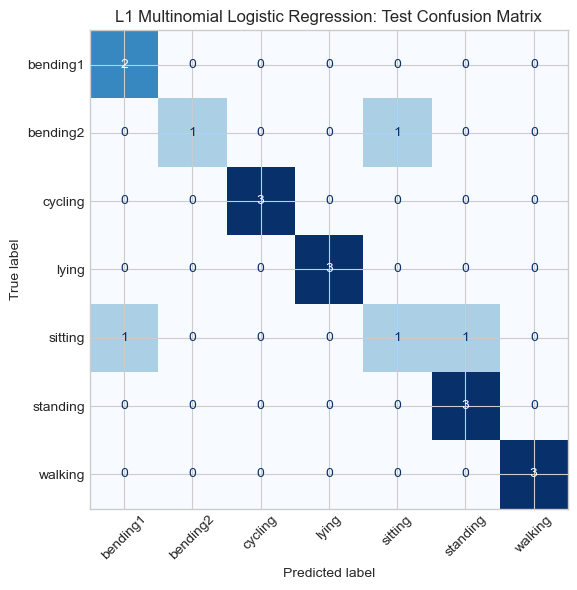

In [19]:
X_train_multi, _, y_train_multi, _ = build_feature_data(
    best_l_multinomial,
    "train",
)
X_test_multi, _, y_test_multi, _ = build_feature_data(
    best_l_multinomial,
    "test",
)

multinomial_test_prediction = best_multinomial_model.predict(X_test_multi)
multinomial_test_probability = best_multinomial_model.predict_proba(X_test_multi)
multinomial_test_error = 1 - accuracy_score(
    y_test_multi,
    multinomial_test_prediction,
)

print("Multinomial logistic test error:", round(multinomial_test_error, 4))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test_multi,
    multinomial_test_prediction,
    labels=ACTIVITIES,
    display_labels=ACTIVITIES,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)
ax.set_title("L1 Multinomial Logistic Regression: Test Confusion Matrix")
plt.tight_layout()
plt.show()


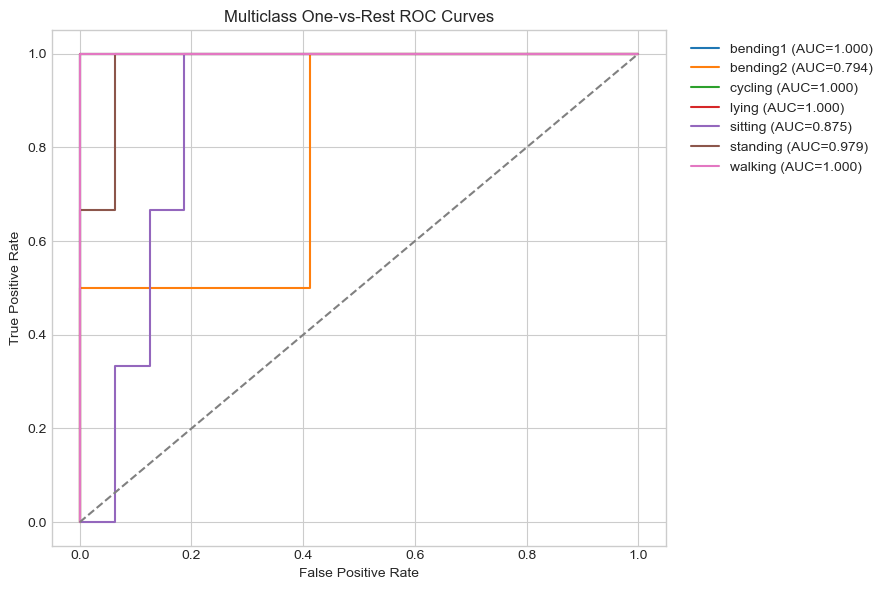

,activity,one_vs_rest_auc
0,bending1,1.0000
1,bending2,0.7941
2,cycling,1.0000
3,lying,1.0000
4,sitting,0.8750
5,standing,0.9792
6,walking,1.0000


In [20]:
# One-vs-rest ROC curves for the seven activities.
multinomial_classes = best_multinomial_model.named_steps["model"].classes_
y_test_binary_matrix = label_binarize(
    y_test_multi,
    classes=multinomial_classes,
)

plt.figure(figsize=(9, 6))
multiclass_auc_rows = []

for class_index, activity in enumerate(multinomial_classes):
    fpr_class, tpr_class, _ = roc_curve(
        y_test_binary_matrix[:, class_index],
        multinomial_test_probability[:, class_index],
    )
    auc_class = roc_auc_score(
        y_test_binary_matrix[:, class_index],
        multinomial_test_probability[:, class_index],
    )
    multiclass_auc_rows.append(
        {"activity": activity, "one_vs_rest_auc": auc_class}
    )
    plt.plot(
        fpr_class,
        tpr_class,
        label=f"{activity} (AUC={auc_class:.3f})",
    )

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass One-vs-Rest ROC Curves")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(pd.DataFrame(multiclass_auc_rows).round(4))


A multiclass confusion matrix compares the actual and predicted activity for
all seven classes. Each ROC curve treats one activity as positive and all
remaining activities as negative.


#### 2(c)(ii) Gaussian and Multinomial Naive Bayes


In [21]:
gaussian_rows = []
multinomial_nb_rows = []

for number_of_segments in range(1, 21):
    X_train_l, _, y_train_l, _ = build_feature_data(
        number_of_segments,
        "train",
    )

    gaussian_score = cross_val_score(
        GaussianNB(),
        X_train_l,
        y_train_l,
        scoring="accuracy",
        cv=multiclass_cv,
        n_jobs=-1,
    ).mean()

    # The AReM features are nonnegative, so MultinomialNB can use them directly.
    multinomial_score = cross_val_score(
        MultinomialNB(),
        X_train_l,
        y_train_l,
        scoring="accuracy",
        cv=multiclass_cv,
        n_jobs=-1,
    ).mean()

    gaussian_rows.append(
        {"l": number_of_segments, "cv_accuracy": gaussian_score}
    )
    multinomial_nb_rows.append(
        {"l": number_of_segments, "cv_accuracy": multinomial_score}
    )

gaussian_results = pd.DataFrame(gaussian_rows)
multinomial_nb_results = pd.DataFrame(multinomial_nb_rows)

best_gaussian_row = gaussian_results.loc[
    gaussian_results["cv_accuracy"].idxmax()
]
best_multinomial_nb_row = multinomial_nb_results.loc[
    multinomial_nb_results["cv_accuracy"].idxmax()
]

display(pd.DataFrame(
    {
        "method": ["Gaussian NB", "Multinomial NB"],
        "best_l": [
            int(best_gaussian_row["l"]),
            int(best_multinomial_nb_row["l"]),
        ],
        "cv_accuracy": [
            best_gaussian_row["cv_accuracy"],
            best_multinomial_nb_row["cv_accuracy"],
        ],
    }
).round(4))


,method,best_l,cv_accuracy
0,Gaussian NB,1,0.8701
1,Multinomial NB,1,0.8423


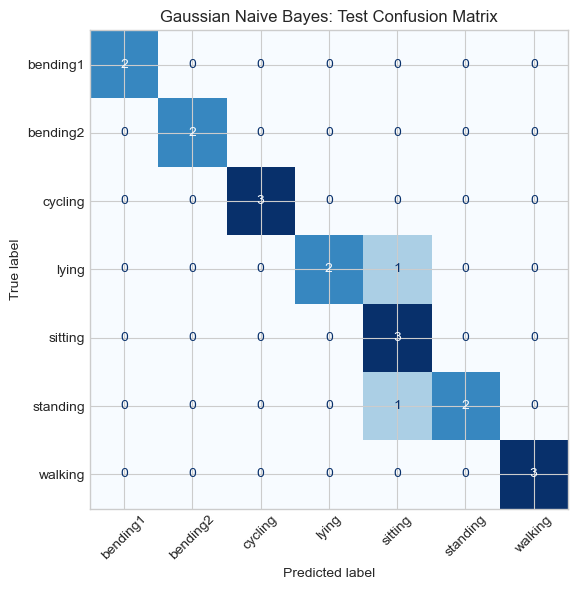

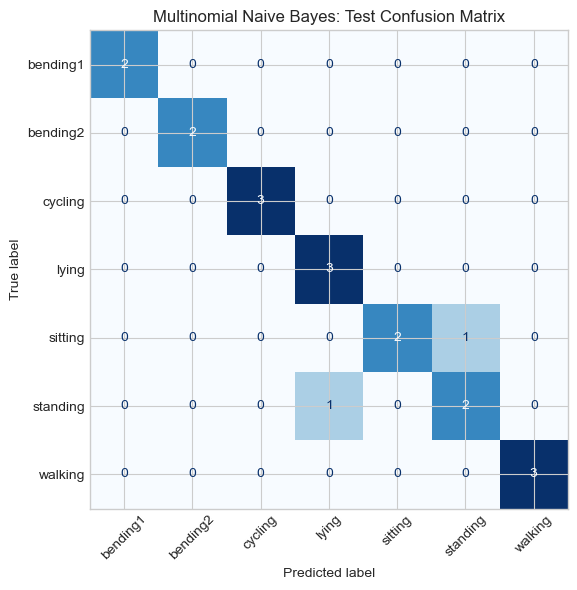

In [22]:
def fit_and_test_naive_bayes(model, best_l, model_name):
    X_train_nb, _, y_train_nb, _ = build_feature_data(best_l, "train")
    X_test_nb, _, y_test_nb, _ = build_feature_data(best_l, "test")

    fitted_model = clone(model).fit(X_train_nb, y_train_nb)
    prediction = fitted_model.predict(X_test_nb)
    test_error = 1 - accuracy_score(y_test_nb, prediction)

    fig, ax = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_test_nb,
        prediction,
        labels=ACTIVITIES,
        display_labels=ACTIVITIES,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{model_name}: Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return fitted_model, test_error


best_l_gaussian = int(best_gaussian_row["l"])
best_l_multinomial_nb = int(best_multinomial_nb_row["l"])

gaussian_model, gaussian_test_error = fit_and_test_naive_bayes(
    GaussianNB(),
    best_l_gaussian,
    "Gaussian Naive Bayes",
)

multinomial_nb_model, multinomial_nb_test_error = fit_and_test_naive_bayes(
    MultinomialNB(),
    best_l_multinomial_nb,
    "Multinomial Naive Bayes",
)


#### 2(c)(iii) Final Multi-Class Comparison


In [23]:
multiclass_comparison = pd.DataFrame(
    {
        "method": [
            "L1 multinomial logistic regression",
            "Gaussian Naive Bayes",
            "Multinomial Naive Bayes",
        ],
        "best_l": [
            best_l_multinomial,
            best_l_gaussian,
            best_l_multinomial_nb,
        ],
        "cv_accuracy": [
            best_multinomial_row["cv_accuracy"],
            best_gaussian_row["cv_accuracy"],
            best_multinomial_nb_row["cv_accuracy"],
        ],
        "test_error": [
            multinomial_test_error,
            gaussian_test_error,
            multinomial_nb_test_error,
        ],
    }
).sort_values("test_error")

display(multiclass_comparison.round(4))
print(
    "Best multiclass method by test error:",
    multiclass_comparison.iloc[0]["method"],
)


,method,best_l,cv_accuracy,test_error
1,Gaussian Naive Bayes,1,0.8701,0.1053
2,Multinomial Naive Bayes,1,0.8423,0.1053
0,L1 multinomial logistic regression,2,0.9134,0.1579


Best multiclass method by test error: Gaussian Naive Bayes


The method with the lowest test error performs best on the held-out activity
instances. Cross-validation accuracy is also shown because the test set is
small, so a difference of one prediction can noticeably change test error.


## 3. ISLR 4.8.3

For class $k$, assume

$$
X \mid Y=k \sim N(\mu_k,\sigma_k^2).
$$

The QDA score for class $k$ is

$$
\delta_k(x)
=
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

After expanding $(x-\mu_k)^2$, we get

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)
+\log(\pi_k).
$$

If the classes have different variances, the coefficient of $x^2$ is different for each class. Therefore, the $x^2$ terms do not cancel when two classes are compared, so the decision boundary is quadratic rather than linear.



## 4. ISLR 4.8.7

Let $D$ represent a company that pays a dividend and $N$ represent a company that does not. The given information is

$$
P(D)=0.8,\qquad P(N)=0.2,
$$

and

$$
X \mid D \sim N(10,6^2),\qquad
X \mid N \sim N(0,6^2).
$$

For a company with $X=4$, Bayes' theorem gives

$$
P(D \mid X=4)
=
\frac{0.8f_D(4)}
{0.8f_D(4)+0.2f_N(4)}.
$$

Because both groups have the same standard deviation, the common part of the normal density cancels. Therefore,

$$
P(D \mid X=4)
=
\frac{0.8e^{-(4-10)^2/(2\cdot6^2)}}
{0.8e^{-(4-10)^2/(2\cdot6^2)}
+0.2e^{-(4-0)^2/(2\cdot6^2)}}.
$$

$$
P(D \mid X=4)\approx 0.7519.
$$

Therefore, the probability that the company pays a dividend is approximately $75.19\%$.